# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [9]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("/home/naba/NLP_Lab11/dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [39]:
# Changed the code slightly

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
questions = df["question"].tolist()


vocab = Counter(word
    for question in questions
    for word in question.split()
)

word_index = {
    word: i + 1
    for i, word in enumerate(vocab)
}

# Convert words to numbers and add padding
sequences = [
    [word_index[word] for word in question.split()]
    for question in questions
]

max_len = max(len(seq) for seq in sequences)

X_task = torch.zeros(len(sequences), max_len, dtype=torch.long)

for i, seq in enumerate(sequences):
    X_task[i, :len(seq)] = torch.tensor(seq)

# Convert labels into tensors
y_task = torch.tensor(
    df["answer_id"].values,
    dtype=torch.long
)


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    
    optimizer.zero_grad()
    outputs, weights = model(X_task)
    loss = nn.functional.cross_entropy(outputs, y_task) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

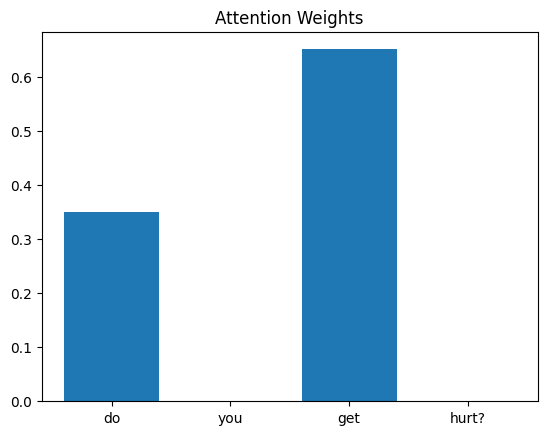

In [ ]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

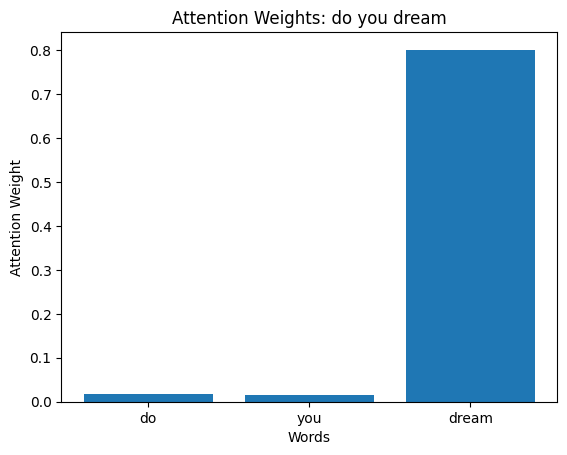

Highest attention word: dream


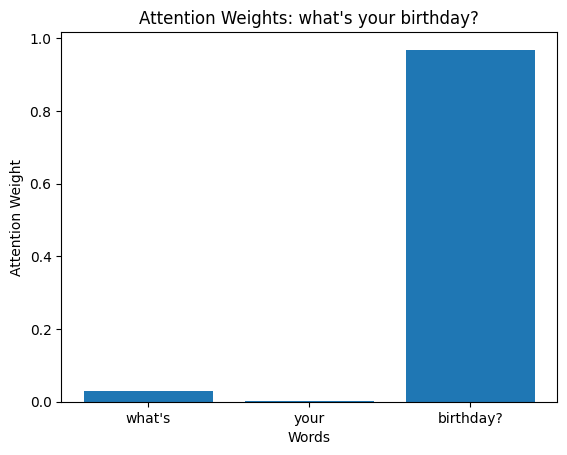

Highest attention word: birthday?


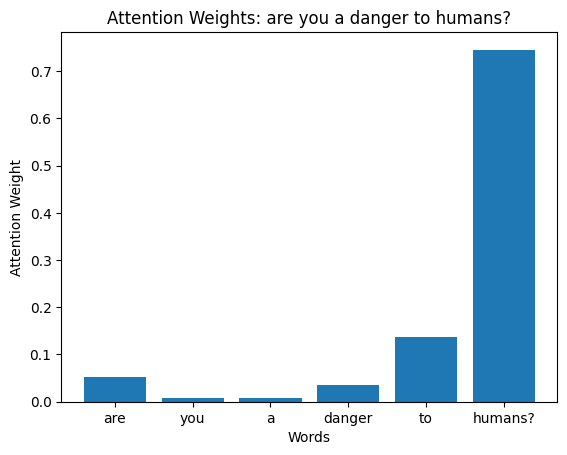

Highest attention word: humans?


In [33]:
model.eval()

questions = df["question"].iloc[[8, 18, 150]]

for question in questions:

    words = question.lower().split()

    sequence = [word_index[word] for word in words]
    padded = sequence + [0] * (max_len - len(sequence))

    input_tensor = torch.tensor([padded])

    with torch.no_grad():
        prediction, weights = model(input_tensor)

    attention_weights = weights[0, :len(words)].tolist()

    plt.bar(words, attention_weights)
    plt.title(f"Attention Weights: {question}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()

    max_index = np.argmax(attention_weights)

    print("Highest attention word:", words[max_index])

The words given highest attentions were distinctive and important to the question meaning in the first two questions, but not really in the third, but they were all the last word.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

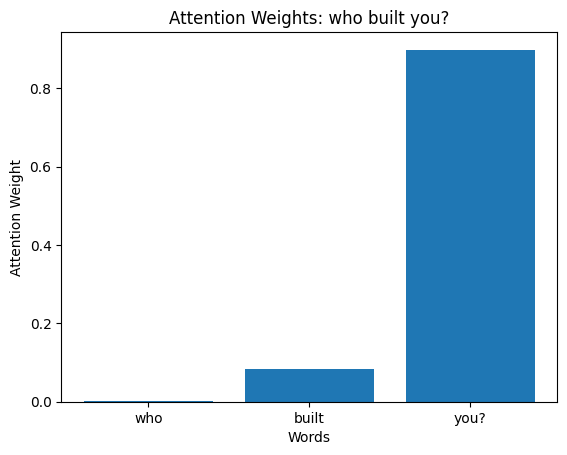

Highest attention word: you?


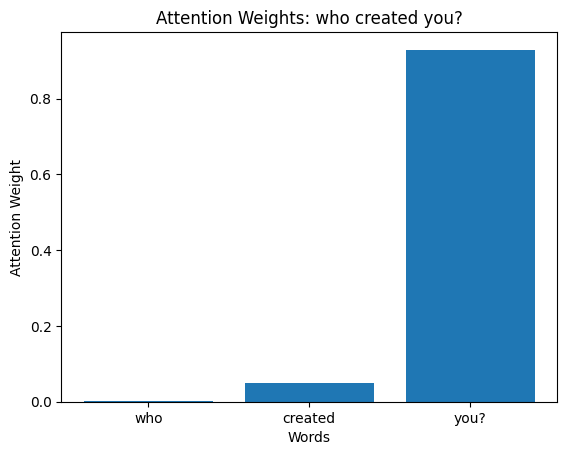

Highest attention word: you?


In [38]:
questions = df["question"].iloc[[46, 48]]

for question in questions:

    words = question.lower().split()

    sequence = [word_index[word] for word in words]
    padded = sequence + [0] * (max_len - len(sequence))

    input_tensor = torch.tensor([padded])

    with torch.no_grad():
        prediction, weights = model(input_tensor)

    attention_weights = weights[0, :len(words)].tolist()

    plt.bar(words, attention_weights)
    plt.title(f"Attention Weights: {question}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()

    max_index = np.argmax(attention_weights)

    print("Highest attention word:", words[max_index])

The model focuses on similar words when processing similar questions. The model gave similar weights to "created" and "built" even that they are differnet word but have similar meaning.